In [122]:
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt     

import seaborn as sns
from pathlib import Path

In [123]:
output_dir = Path("outputs")

output_dir.mkdir(exist_ok=True)
print(" folder created succesfully")

 folder created succesfully


In [124]:
train= pd.read_csv("train.csv")
test= pd.read_csv("test.csv")

print(" Training dataset", train.shape)

print("Testing dataset", test.shape)

print(train.head())

 Training dataset (891, 12)
Testing dataset (418, 11)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4

In [125]:
print(train.columns)

train.info()


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [126]:
print(train.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [127]:
print(train["Survived"].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


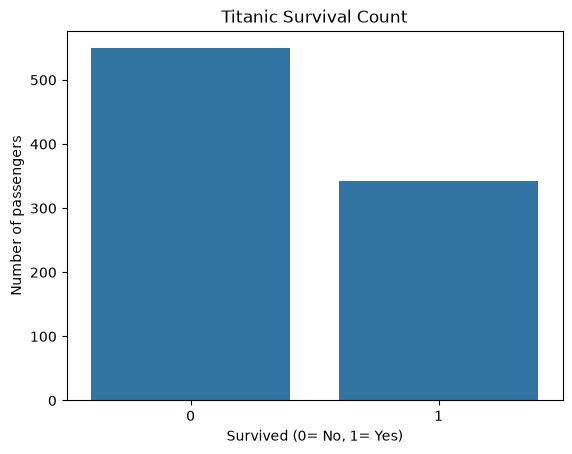

In [128]:
sns.countplot(data=train, x="Survived")
plt.title("Titanic Survival Count")
plt.xlabel("Survived (0= No, 1= Yes)")
plt.ylabel("Number of passengers")

plt.show()


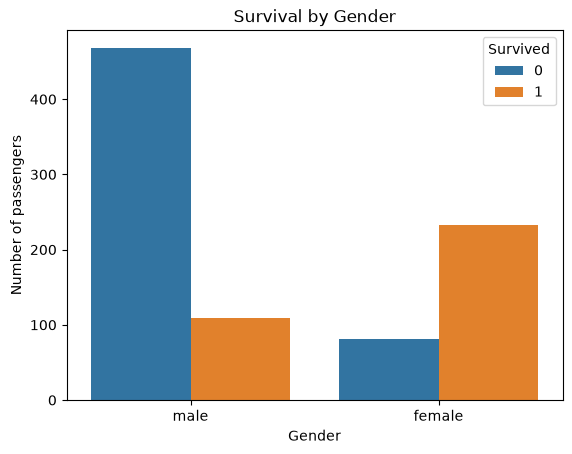

In [129]:
fig, ax =plt.subplots()

sns.countplot(
    data=train,
     x= "Sex",
     hue="Survived",
    ax=ax
 )
ax.set_title("Survival by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Number of passengers")
plt.show()

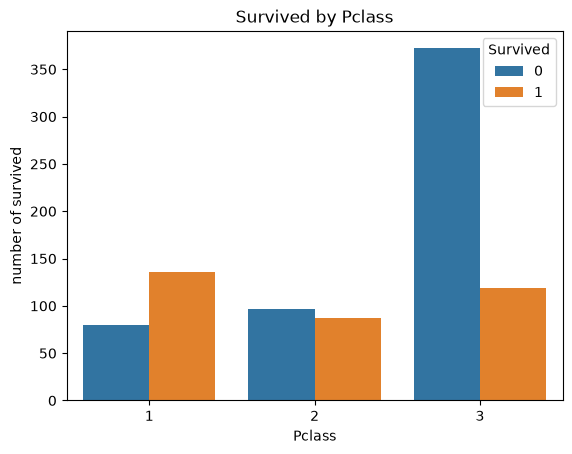

In [130]:
fig, ax =plt.subplots()
sns.countplot(
    data=train,
    x= "Pclass",
    hue="Survived",
    ax=ax
)
ax.set_title("Survived by Pclass")
ax.set_xlabel("Pclass")
ax.set_ylabel("number of survived")

plt.show()

In [131]:
survival_rate= train.groupby("Pclass")["Survived"].mean() *100
print(survival_rate)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


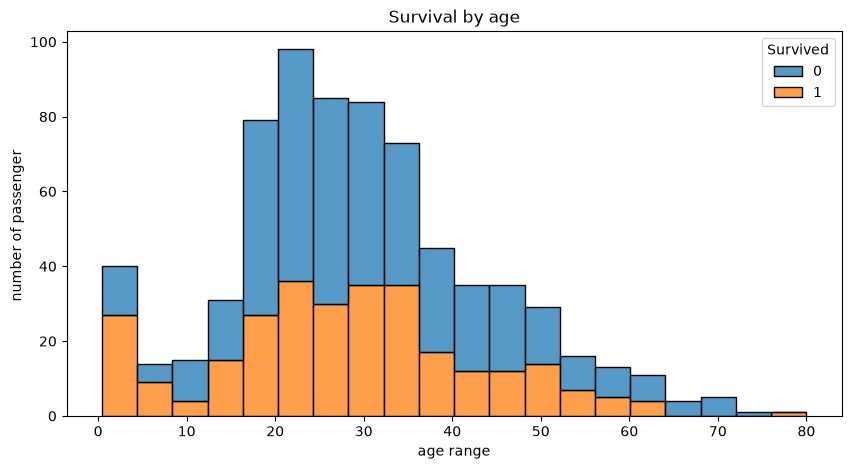

In [132]:
fig, ax= plt.subplots(figsize=(10, 5))
sns.histplot(
    data=train,
    x="Age",
    bins=20,
    hue="Survived",
    multiple="stack",
    ax=ax
)
ax.set_title("Survival by age")
ax.set_xlabel("age range")
ax.set_ylabel("number of passenger ")
plt.show()

In [133]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [134]:
train["Age"].median()

np.float64(28.0)

In [135]:
train["Age"] = train["Age"]. fillna(train["Age"].median())

train["Age"].isnull().sum()

np.int64(0)

In [136]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [137]:
train["Embarked"].mode()
train["Embarked"]= train["Embarked"]. fillna(train["Embarked"].mode()[0])
train["Embarked"].isnull().sum()

np.int64(0)

In [138]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [139]:
train = train.drop(columns=["Cabin"])





In [140]:
train.columns

train.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [141]:
train["Sex"]= train["Sex"].map({
    "male" : 0,
    "female" : 1
})
train["Sex"].head()

0    0
1    1
2    1
3    1
4    0
Name: Sex, dtype: int64

In [142]:
train["Embarked"]= train["Embarked"].map({
    "S" : 0,
    "C" : 1,
    "Q" : 2
})

train[["Sex", "Embarked"]].head()

,Sex,Embarked
0,0,0
1,1,1
2,1,0
3,1,0
4,0,0


In [143]:
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1


In [144]:
train[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [145]:
train["IsAlone"] = (train["FamilySize"] == 1).astype(int)

In [146]:
train[["FamilySize", "IsAlone"]].head(10)

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1
5,1,1
6,1,1
7,5,0
8,3,0
9,2,0


In [147]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "IsAlone"
]
X= train[features]
y= train ["Survived"]

In [148]:
print(X.shape)
print(y.shape)

(891, 9)
(891,)


In [149]:
from sklearn.model_selection import train_test_split
X_train, X_val ,y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state= 42,
    stratify= y
 )

In [150]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (712, 9)
X_val: (179, 9)
y_train: (712,)
y_val: (179,)


In [151]:
train_clean= pd.read_csv("train.csv")
print(train_clean.shape)

(891, 12)


In [152]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
    
]
X= train_clean[features]
y= train_clean ["Survived"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state=42,
    stratify=y
)

In [153]:
import pandas as pd
from sklearn.model_selection import train_test_split

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

for df in [train, test]:
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked",
    "FamilySize", "IsAlone"
]

X = train[features]
y = train["Survived"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_val.shape)

(712, 9)
(179, 9)


In [154]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone"
]

categorical_features = [
    "Sex",
    "Embarked"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [155]:
X_train_ready = preprocessor.fit_transform(X_train)
X_val_ready = preprocessor.transform(X_val)
print(X_train_ready.shape)
print(X_val_ready.shape)  

(712, 12)
(179, 12)


In [156]:
from sklearn.linear_model import LogisticRegression
model= LogisticRegression(max_iter=1000)
model.fit(X_train_ready, y_train)
print("Model Trained Successfully!")

Model Trained Successfully!


In [157]:
y_pred = model.predict(X_val_ready)
print(y_pred[:10])

[0 0 0 0 1 1 1 0 0 0]


In [158]:
from sklearn.metrics import accuracy_score
accuracy= accuracy_score(y_val, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8044692737430168


In [159]:
print(f"Model Accuracy:{accuracy * 100: .2f}%")

Model Accuracy: 80.45%


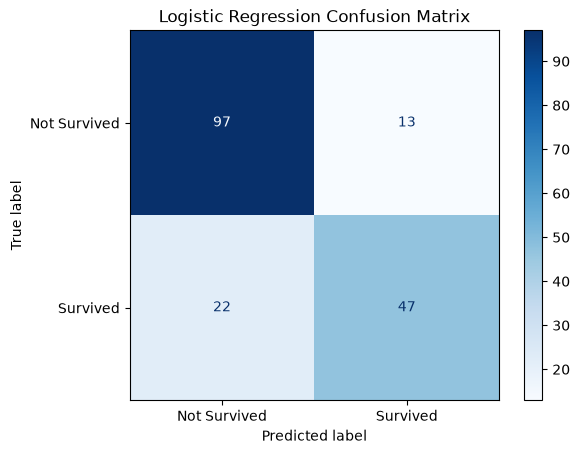

In [160]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["Not Survived", "Survived"],
    cmap="Blues"
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [161]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators= 100,
    random_state=42
)
rf_model.fit(X_train_ready, y_train)
print("Random Forest trained successfully!")

Random Forest trained successfully!


In [162]:
rf_pred = rf_model.predict(X_val_ready)
rf_accuracy =accuracy_score(y_val, rf_pred)
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

Random Forest Accuracy: 82.12%


In [163]:
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Model Accuracy:{accuracy * 100: .2f}%")

Random Forest Accuracy: 82.12%
Model Accuracy: 80.45%


In [164]:
import xgboost
print(xgboost.__version__)

3.4.1


In [165]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)
xgb_model.fit(X_train_ready, y_train)
print("XGBoost trained.successfully!")

XGBoost trained.successfully!


In [166]:
xgb_pred = xgb_model.predict(X_val_ready)
xgb_accuracy = accuracy_score(y_val, xgb_pred)
print(f"XGBoost Accurac: {xgb_accuracy * 100 : .2f}%")

XGBoost Accurac:  80.45%


In [167]:
print(f"XGBoost Accurac: {xgb_accuracy * 100 : .2f}%")
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Model Accuracy:{accuracy * 100: .2f}%")

XGBoost Accurac:  80.45%
Random Forest Accuracy: 82.12%
Model Accuracy: 80.45%


In [168]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV Accuracy: 0.8203092681965922


In [169]:
best_rf = grid_search.best_estimator_

best_pred = best_rf.predict(X_val)

best_accuracy = accuracy_score(y_val, best_pred)

print(f"Original Random Forest: {rf_accuracy * 100:.2f}%")
print(f"Tuned Random Forest:    {best_accuracy * 100:.2f}%")

Original Random Forest: 82.12%
Tuned Random Forest:    81.01%


In [170]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

final_model.fit(X, y)

print("Final model trained successfully!")

Final model trained successfully!


In [171]:
X_test = test[features]

test_predictions = final_model.predict(X_test)

print(test_predictions[:10])
print(len(test_predictions))

[0 0 0 1 0 0 0 0 1 0]
418


In [172]:
submission = pd.DataFrame({
    "PassengerId" : test["PassengerId"],
    "Survived" : test_predictions
})
submission.to_csv("submission.csv", index=False)
print(submission.head())
print(submission.shape)

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         1
4          896         0
(418, 2)


In [173]:
check =pd.read_csv("submission.csv")
print(check.shape)
print(check.isnull().sum() )
print(check["Survived"].unique())

(418, 2)
PassengerId    0
Survived       0
dtype: int64
[0 1]
